# Predicción de abandono de clientes — Telco Customer Churn
**Asignatura:** MLY1101 Machine Learning · **Evaluación Parcial N°2** · **Caso A**

Notebook reproducible que acompaña al informe técnico (`README.md`). Sigue la metodología **CRISP-DM**:

| Fase CRISP-DM | Sección del notebook |
|---|---|
| 1. Comprensión del negocio | §1 |
| 2. Comprensión de los datos (EDA) | §2 |
| 3. Preparación de los datos | §3 |
| 4. Modelado supervisado | §4 |
| 4b. Modelado no supervisado | §5 |
| 5. Evaluación (técnica, de negocio y ética) | §6 |
| 6. Despliegue (persistencia del modelo) | §7 |

> Ejecutar con *Kernel → Restart & Run All* desde la carpeta `notebooks/`. Todas las rutas son relativas y la semilla es fija (`RANDOM_STATE = 42`).

In [1]:
# Librerías
import warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             silhouette_score, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

BASE = Path("..")
DATA_PATH = BASE / "data" / "Telco_Customer_Churn_Dataset.csv"
IMG_DIR = BASE / "images"; IMG_DIR.mkdir(exist_ok=True)
MODEL_DIR = BASE / "models"; MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
COLORES = {"No": "#4C72B0", "Yes": "#C44E52"}

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(IMG_DIR / f"{nombre}.png", dpi=110, bbox_inches="tight")
    plt.show()

print("Entorno listo")

Entorno listo


## 1. Comprensión del negocio

**Problema.** Una empresa de telecomunicaciones pierde clientes (*churn*) cada mes. Captar un cliente nuevo cuesta varias veces más que retener uno existente, por lo que el área comercial necesita **anticipar qué clientes van a abandonar** para dirigirles acciones de retención (descuentos, upgrade de contrato, soporte técnico) antes de que se vayan.

**Pregunta de negocio.** ¿Qué clientes tienen mayor probabilidad de abandonar y qué características los distinguen?

**Tipo de problema de ML.** Clasificación binaria supervisada (`Churn` = Yes/No) + segmentación no supervisada de la cartera.

**Objetivos**
- *General:* construir un modelo que identifique clientes con alta probabilidad de abandono para priorizar campañas de retención.
- *Específicos:* (1) identificar los factores asociados al churn mediante EDA; (2) entrenar y comparar dos modelos supervisados; (3) segmentar clientes con K-Means para diseñar acciones diferenciadas; (4) traducir las métricas en impacto económico y revisar sesgos.

**KPIs definidos**

| Tipo | KPI | Meta |
|---|---|---|
| Modelo | Recall de la clase churn (clientes que se van y el modelo detecta) | ≥ 0,75 |
| Modelo | ROC-AUC en test | ≥ 0,80 |
| Modelo | Lift del 20 % de clientes con mayor riesgo | ≥ 2,0 |
| Negocio | Tasa de churn mensual (línea base 26,5 %) | Reducir |
| Negocio | Ingreso mensual en riesgo (USD de clientes que abandonan) | Capturar ≥ 70 % con el modelo |
| Negocio | Beneficio neto estimado de la campaña de retención | > 0 y mayor que “contactar a todos” |
| Ética | Diferencia de recall entre grupos de género | < 5 p.p. |

## 2. Comprensión de los datos y análisis exploratorio (EDA)
### 2.1 Carga y estructura

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Dimensiones:", df_raw.shape)
display(df_raw.head())
df_raw.info()

Dimensiones: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Diccionario de variables** (fuente: IBM Sample Data Sets, publicado en Kaggle como *Telco Customer Churn*). Cada fila es un cliente.

| Grupo | Variables |
|---|---|
| Identificador | `customerID` |
| Demográficas | `gender`, `SeniorCitizen` (0/1), `Partner`, `Dependents` |
| Cuenta | `tenure` (meses de antigüedad), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| Servicios | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Objetivo | `Churn` (Yes = abandonó en el último mes) |

### 2.2 Calidad de datos

In [3]:
calidad = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "vacios_texto": (df_raw.astype(str).apply(lambda s: s.str.strip()) == "").sum(),
    "valores_unicos": df_raw.nunique(),
})
display(calidad)
print("Filas duplicadas:", df_raw.duplicated().sum())
print("customerID duplicados:", df_raw["customerID"].duplicated().sum())

tc_num = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
print("\nTotalCharges no numéricos:", tc_num.isna().sum())
display(df_raw.loc[tc_num.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

,tipo,nulos,vacios_texto,valores_unicos
customerID,str,0,0,7043
gender,str,0,0,2
SeniorCitizen,int64,0,0,2
Partner,str,0,0,2
Dependents,str,0,0,2
tenure,int64,0,0,73
PhoneService,str,0,0,2
MultipleLines,str,0,0,3
InternetService,str,0,0,3
OnlineSecurity,str,0,0,3


Filas duplicadas: 0
customerID duplicados: 0

TotalCharges no numéricos: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Hallazgos de calidad**
- No hay nulos explícitos ni duplicados (7.043 clientes únicos).
- `TotalCharges` viene como texto: **11 registros tienen un espacio en blanco**. Todos tienen `tenure = 0`, es decir, son clientes recién incorporados que aún no han sido facturados → el valor correcto es **0**, no un dato faltante aleatorio (se imputa con 0 en §3).
- `SeniorCitizen` está codificada 0/1 mientras el resto de binarias usa Yes/No; se trata como categórica.
- Las categorías “No internet service” / “No phone service” son redundantes con `InternetService` / `PhoneService`.

### 2.3 Variable objetivo

Churn
No     5174
Yes    1869
Churn
No     73.46
Yes    26.54


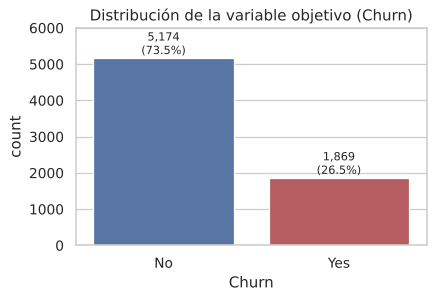

Ingreso mensual de clientes que abandonan: USD 139,131 (30.5% del ingreso mensual total)


In [4]:
df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)

tasa = df["Churn"].value_counts(normalize=True)
print(df["Churn"].value_counts().to_string()); print((tasa*100).round(2).to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Churn", palette=COLORES, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}\n({p.get_height()/len(df):.1%})", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la variable objetivo (Churn)"); ax.set_ylim(0, 6000)
guardar_fig("01_distribucion_churn")

ingreso_riesgo = df.loc[df.Churn == "Yes", "MonthlyCharges"].sum()
print(f"Ingreso mensual de clientes que abandonan: USD {ingreso_riesgo:,.0f} "
      f"({ingreso_riesgo/df.MonthlyCharges.sum():.1%} del ingreso mensual total)")

El dataset está **desbalanceado** (≈ 73/27). Por eso la *accuracy* no es una métrica adecuada (un modelo que dice siempre “No” acierta 73 %); usaremos **recall, F1, ROC-AUC y PR-AUC**, partición estratificada y `class_weight="balanced"`.

### 2.4 Variables numéricas

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


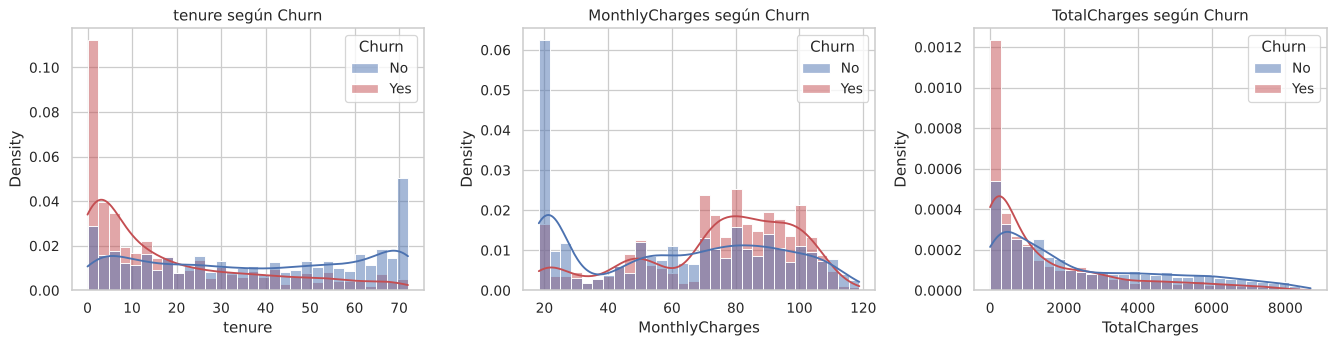

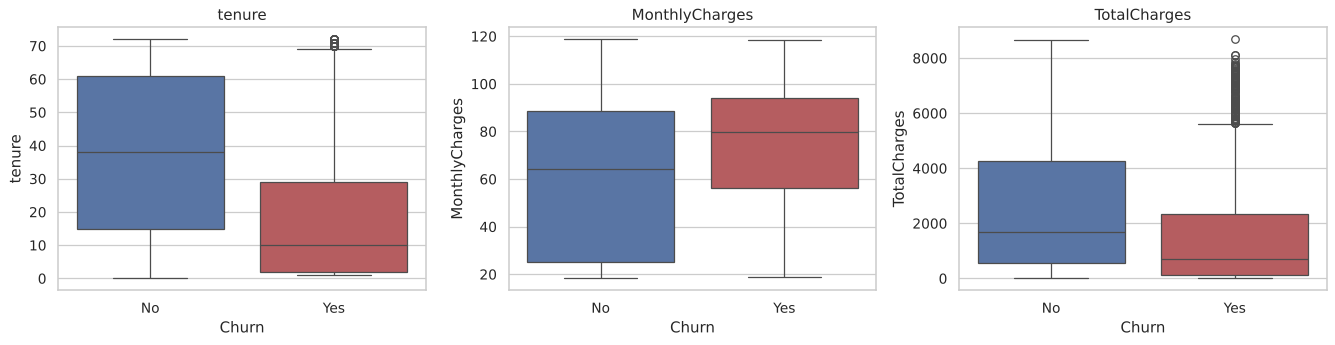

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


In [5]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[num_cols].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, kde=True, palette=COLORES, stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{col} según Churn")
guardar_fig("02_numericas_vs_churn")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, palette=COLORES, ax=ax); ax.set_title(col)
guardar_fig("03_boxplots_numericas")
display(df.groupby("Churn")[num_cols].median().round(1))

- **`tenure`**: los clientes que abandonan son mayoritariamente **nuevos** (mediana ≈ 10 meses vs ≈ 38 de los que se quedan). El riesgo se concentra en el primer año.
- **`MonthlyCharges`**: los que abandonan pagan **más** por mes (mediana ≈ 80 vs ≈ 64 USD).
- **`TotalCharges`** es menor en churners porque depende de la antigüedad (≈ tenure × MonthlyCharges). No se observan outliers fuera de rango de negocio (boxplots), por lo que no se eliminan registros.

### 2.5 Variables categóricas: tasa de churn por categoría

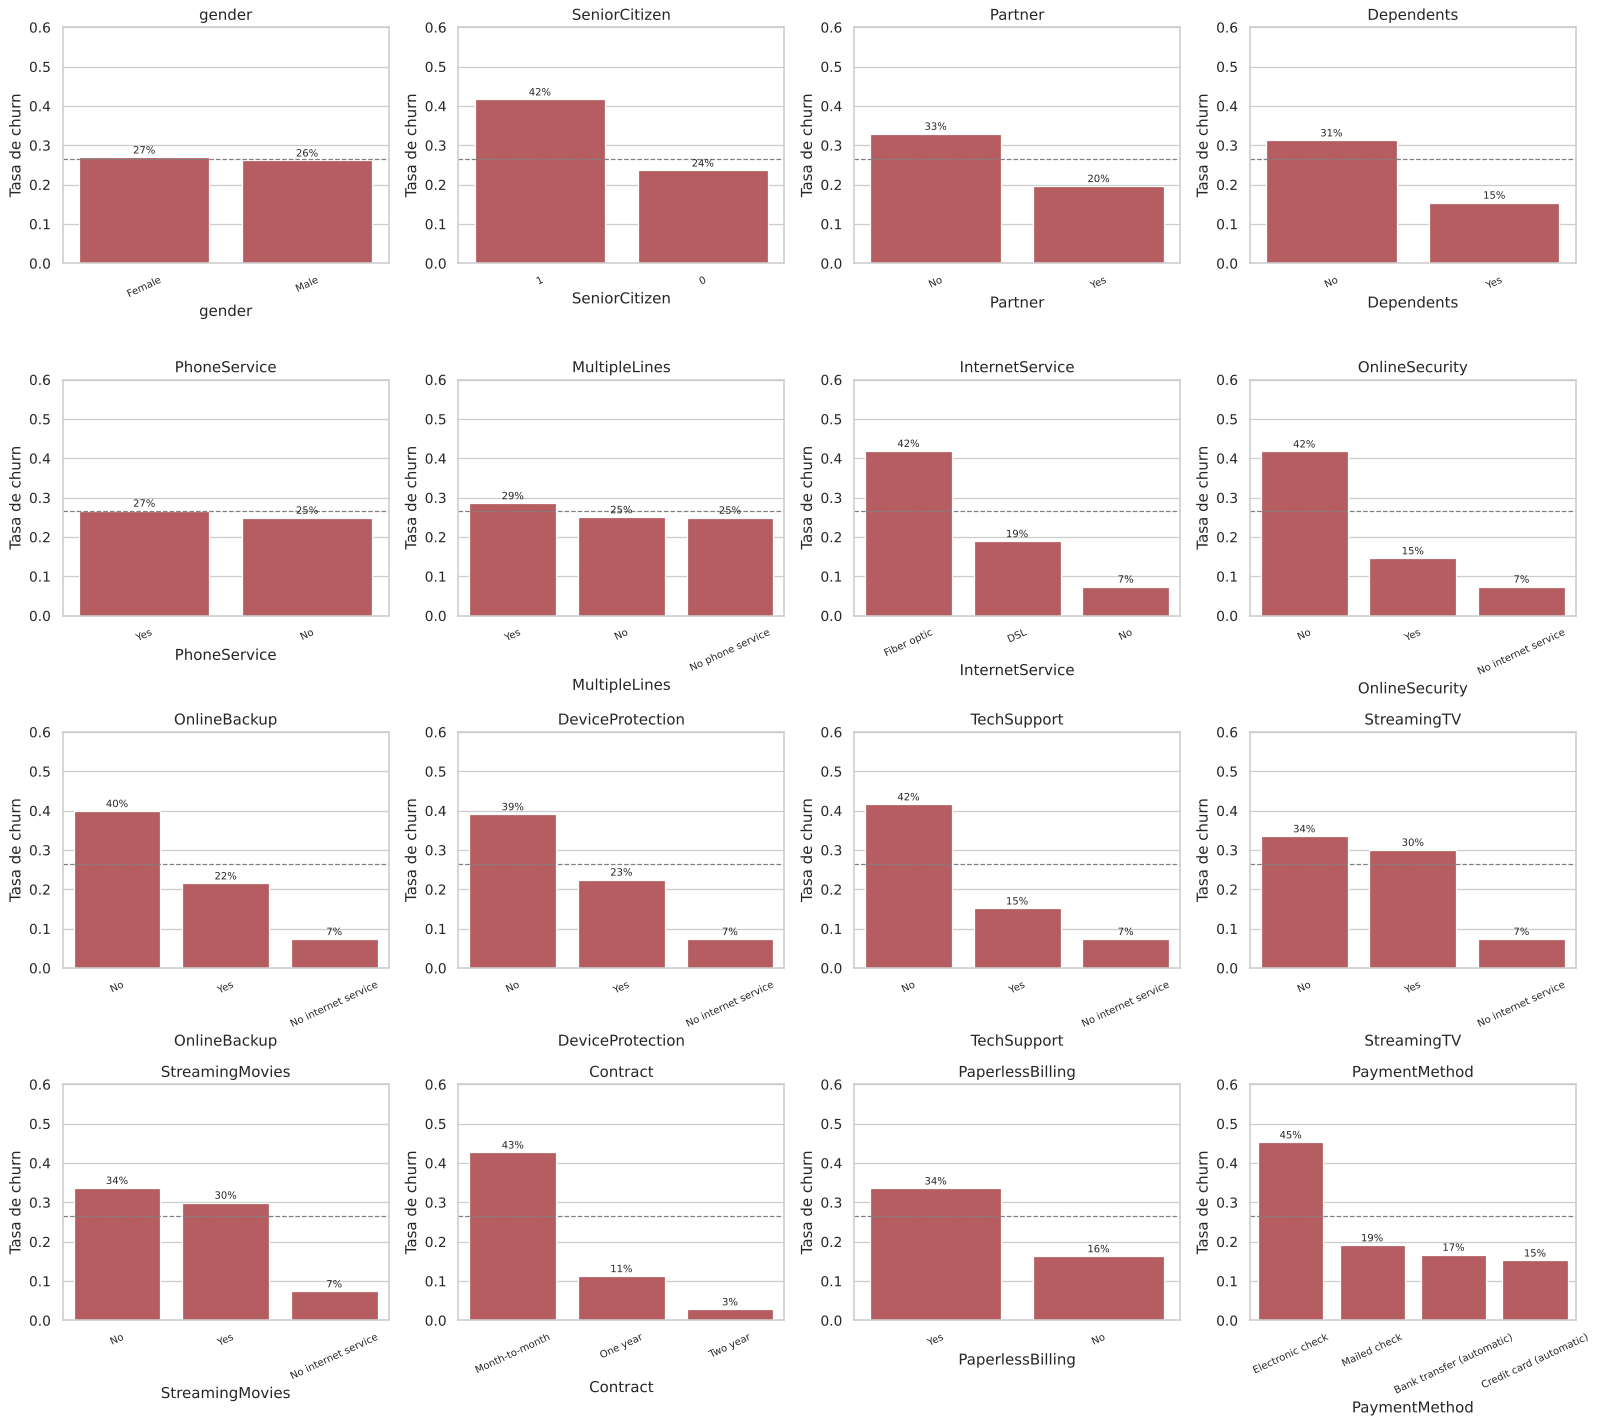

In [6]:
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]
df["churn_bin"] = (df["Churn"] == "Yes").astype(int)

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, col in zip(axes.ravel(), cat_cols):
    t = df.groupby(col)["churn_bin"].mean().sort_values(ascending=False)
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax, color="#C44E52")
    ax.axhline(df.churn_bin.mean(), ls="--", c="gray", lw=1)
    ax.set_title(col); ax.set_ylabel("Tasa de churn"); ax.set_ylim(0, 0.6)
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    for i, v in enumerate(t.values): ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=8)
guardar_fig("04_tasa_churn_categoricas")

In [7]:
# Ranking de variables por diferencia de tasa de churn entre categorías (max - min)
rango = {c: df.groupby(c)["churn_bin"].mean().max() - df.groupby(c)["churn_bin"].mean().min() for c in cat_cols}
ranking = pd.Series(rango).sort_values(ascending=False).rename("diferencia_tasa_churn").to_frame()
display(ranking.round(3))

,diferencia_tasa_churn
Contract,0.399
InternetService,0.345
OnlineSecurity,0.344
TechSupport,0.342
OnlineBackup,0.325
DeviceProtection,0.317
PaymentMethod,0.300
StreamingMovies,0.263
StreamingTV,0.261
SeniorCitizen,0.181


**Patrones principales**
1. **Tipo de contrato** es el factor más fuerte: *Month-to-month* ≈ 43 % de churn vs *One year* ≈ 11 % y *Two year* ≈ 3 %.
2. **Servicios de protección/soporte** (`OnlineSecurity`, `TechSupport`): quienes **no** los tienen abandonan ≈ 2,5–3 veces más.
3. **Internet de fibra óptica**: ≈ 42 % de churn (vs 19 % DSL) → posible problema de precio/calidad del servicio de fibra.
4. **Pago con cheque electrónico**: ≈ 45 % vs ≈ 15–17 % con pagos automáticos.
5. **Adultos mayores** (≈ 42 %) y clientes **sin pareja ni dependientes** abandonan más.
6. `gender` y `PhoneService` prácticamente **no** discriminan (diferencia < 1 p.p.).

### 2.6 Interacciones y correlaciones

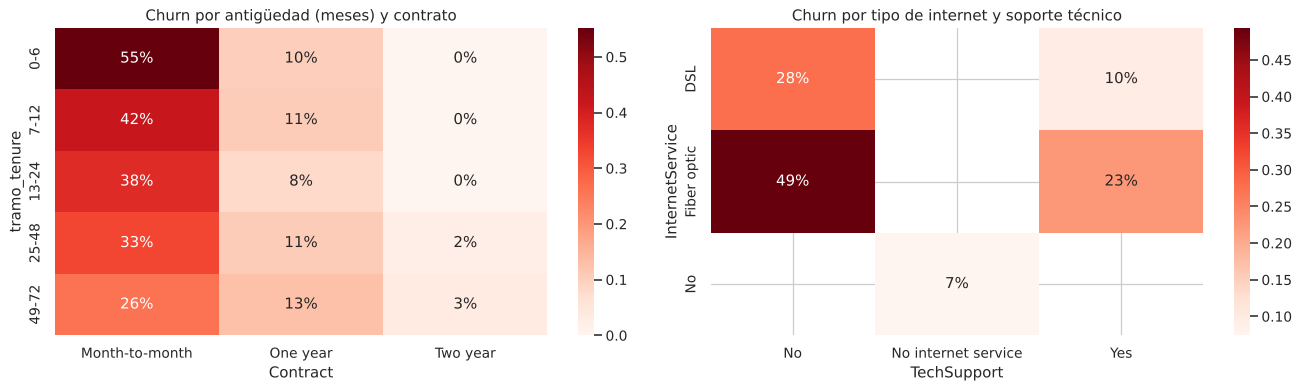

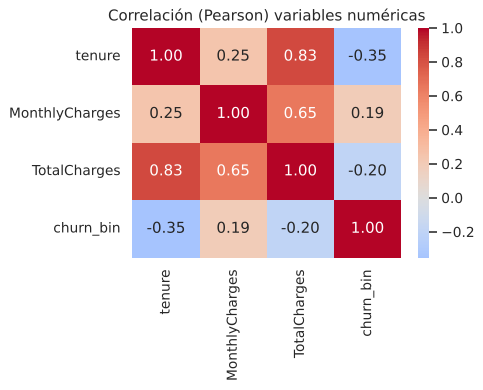

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
df["tramo_tenure"] = pd.cut(df.tenure, bins=[-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
t = df.pivot_table(index="tramo_tenure", columns="Contract", values="churn_bin", aggfunc="mean")
sns.heatmap(t, annot=True, fmt=".0%", cmap="Reds", ax=axes[0]); axes[0].set_title("Churn por antigüedad (meses) y contrato")
t2 = df.pivot_table(index="InternetService", columns="TechSupport", values="churn_bin", aggfunc="mean")
sns.heatmap(t2, annot=True, fmt=".0%", cmap="Reds", ax=axes[1]); axes[1].set_title("Churn por tipo de internet y soporte técnico")
guardar_fig("05_interacciones")

corr = df[num_cols + ["churn_bin"]].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Correlación (Pearson) variables numéricas")
guardar_fig("06_correlacion_numericas")
df = df.drop(columns=["tramo_tenure"])

- El churn cae fuertemente con la antigüedad **dentro de cada tipo de contrato**; el peor segmento es *month-to-month* con menos de 6 meses.
- `TotalCharges` está muy correlacionada con `tenure` (≈ 0,83): hay **multicolinealidad**, relevante para la regresión logística (se resuelve en §3 excluyendo `TotalCharges`).
- `tenure` tiene correlación negativa con el churn (≈ −0,35) y `MonthlyCharges` positiva (≈ 0,19).

## 3. Preparación y transformación de los datos

Decisiones (justificadas en el EDA):

| Paso | Decisión | Motivo |
|---|---|---|
| Limpieza | `TotalCharges` → numérico, blancos = 0 | Son clientes con `tenure = 0` aún no facturados |
| Exclusión | `customerID` | Identificador sin valor predictivo (y dato personal) |
| Exclusión ética | `gender` | Atributo protegido sin relación con el churn (EDA: < 1 p.p.); se conserva **solo para auditar sesgo** |
| Exclusión por multicolinealidad | `TotalCharges` | ≈ `tenure` × `MonthlyCharges` (r = 0,83 con `tenure`); distorsiona los coeficientes de la regresión logística y su exclusión no reduce el ROC-AUC en CV (0,846 → 0,845) |
| Recodificación | “No internet service” / “No phone service” → “No” | Información redundante con `InternetService` y `PhoneService`; evita columnas duplicadas tras el One-Hot |
| Tipo | `SeniorCitizen` 0/1 → “No”/“Yes” | Es una categoría, no una magnitud |
| Ingeniería (segmentación) | `num_servicios`, `pago_automatico`, `contrato_ord`, `fibra` | Resumen de vinculación del cliente usado en K-Means (§5). No se agregan al modelo supervisado porque son combinación lineal de columnas ya incluidas |
| Codificación | One-Hot Encoding de categóricas (`handle_unknown="ignore"`) | Algoritmos de sklearn requieren entradas numéricas |
| Escalado | `StandardScaler` en numéricas | Necesario para Regresión Logística y K-Means (sensibles a la escala) |
| Partición | 80 % train / 20 % test **estratificada** | Mantener la proporción 73/27 en ambos conjuntos |
| Fuga de datos | Todo el preprocesamiento va dentro de un `Pipeline` | Se ajusta solo con train (también dentro de cada fold de CV) |

In [9]:
servicios = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]

def ingenieria_variables(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0.0)
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"}).fillna(d["SeniorCitizen"]).astype(str)
    d = d.replace({"No internet service": "No", "No phone service": "No"})
    d["num_servicios"] = (d[servicios] == "Yes").sum(axis=1)
    d["pago_automatico"] = d["PaymentMethod"].str.contains("automatic").map({True: "Yes", False: "No"})
    return d

datos = ingenieria_variables(df_raw)
y = (datos["Churn"] == "Yes").astype(int)
grupo_sensible = datos[["gender", "SeniorCitizen"]]           # solo para auditoría ética
COLS_EXCLUIDAS = ["customerID", "Churn", "gender", "TotalCharges", "num_servicios", "pago_automatico"]
X = datos.drop(columns=COLS_EXCLUIDAS)

NUM_FEATURES = ["tenure", "MonthlyCharges"]
CAT_FEATURES = [c for c in X.columns if c not in NUM_FEATURES]
print("Numéricas:", NUM_FEATURES); print("Categóricas:", CAT_FEATURES)

X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, grupo_sensible, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"\nTrain: {X_train.shape}  churn={y_train.mean():.3f}")
print(f"Test : {X_test.shape}  churn={y_test.mean():.3f}")

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT_FEATURES),
])
n_feat = preprocesador.fit(X_train).transform(X_train.head()).shape[1]
print("Nº de variables después de One-Hot:", n_feat)

Numéricas: ['tenure', 'MonthlyCharges']
Categóricas: ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train: (5634, 17)  churn=0.265
Test : (1409, 17)  churn=0.265
Nº de variables después de One-Hot: 24


In [10]:
# Evidencia para excluir TotalCharges: ROC-AUC (CV 5 folds, train) de una Regresión Logística con y sin la variable
from sklearn.model_selection import cross_val_score
for nums in [["tenure", "MonthlyCharges", "TotalCharges"], NUM_FEATURES]:
    Xc = X_train.join(datos.loc[X_train.index, ["TotalCharges"]]) if "TotalCharges" in nums else X_train
    prep_c = ColumnTransformer([("num", StandardScaler(), nums), ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT_FEATURES)])
    pipe_c = Pipeline([("prep", prep_c), ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000))])
    auc = cross_val_score(pipe_c, Xc, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc").mean()
    print(f"Numéricas={nums}  ->  ROC-AUC CV = {auc:.4f}")

Numéricas=['tenure', 'MonthlyCharges', 'TotalCharges']  ->  ROC-AUC CV = 0.8461
Numéricas=['tenure', 'MonthlyCharges']  ->  ROC-AUC CV = 0.8449


## 4. Modelado supervisado

Se comparan **dos algoritmos de naturaleza distinta** + una línea base:

| Modelo | Por qué se eligió | Configuración |
|---|---|---|
| `DummyClassifier` | Línea base: predice la clase mayoritaria. Cualquier modelo útil debe superarla. | — |
| **Regresión Logística** | Modelo lineal **interpretable** (coeficientes = dirección y fuerza del efecto, odds ratios), rápido y estándar en churn; entrega probabilidades calibradas. | Regularización L1/L2, `C` ajustado, `class_weight="balanced"` |
| **Random Forest** | Ensamble de árboles que captura **no linealidades e interacciones** (p. ej. contrato × antigüedad vistas en el EDA), robusto a multicolinealidad y outliers, entrega importancia de variables. | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` ajustados, `class_weight="balanced"` |

**Selección de hiperparámetros:** `GridSearchCV` con validación cruzada **estratificada de 5 folds** sobre train, métrica **ROC-AUC** (independiente del umbral y robusta al desbalance). El conjunto de test no se usa hasta la evaluación final.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_lr = Pipeline([("prep", preprocesador),
                    ("modelo", LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000, random_state=RANDOM_STATE))])
grid_lr = {"modelo__C": [0.01, 0.1, 0.5, 1, 5], "modelo__penalty": ["l1", "l2"]}

pipe_rf = Pipeline([("prep", preprocesador),
                    ("modelo", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))])
grid_rf = {"modelo__n_estimators": [300], "modelo__max_depth": [6, 10, None],
           "modelo__min_samples_leaf": [5, 10, 20], "modelo__max_features": ["sqrt", 0.3]}

busquedas = {}
for nombre, pipe, grid in [("Regresión Logística", pipe_lr, grid_lr), ("Random Forest", pipe_rf, grid_rf)]:
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    print(f"{nombre}: ROC-AUC CV = {gs.best_score_:.4f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.4f}")
    print("   Mejores hiperparámetros:", {k.replace('modelo__', ''): v for k, v in gs.best_params_.items()})

dummy = Pipeline([("prep", preprocesador), ("modelo", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
modelos = {"Baseline (Dummy)": dummy, **{k: v.best_estimator_ for k, v in busquedas.items()}}

Regresión Logística: ROC-AUC CV = 0.8451 ± 0.0123
   Mejores hiperparámetros: {'C': 5, 'penalty': 'l2'}
Random Forest: ROC-AUC CV = 0.8476 ± 0.0103
   Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 20, 'n_estimators': 300}


### 4.1 Selección del umbral de decisión
Con `class_weight="balanced"` el umbral 0,5 ya favorece el recall, pero el umbral óptimo depende del negocio. Para **no usar el test**, se obtienen probabilidades *out-of-fold* en train (`cross_val_predict`) y se elige el umbral que **maximiza F1 sujeto a recall ≥ 0,75** (KPI).

In [12]:
umbrales = {"Baseline (Dummy)": 0.5}
for nombre in ["Regresión Logística", "Random Forest"]:
    oof = cross_val_predict(modelos[nombre], X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    validos = rec[:-1] >= 0.75
    idx = np.argmax(np.where(validos, f1[:-1], -1))
    umbrales[nombre] = float(thr[idx])
    print(f"{nombre}: umbral={thr[idx]:.3f}  recall OOF={rec[idx]:.3f}  precisión OOF={prec[idx]:.3f}  F1 OOF={f1[idx]:.3f}")

Regresión Logística: umbral=0.557  recall OOF=0.754  precisión OOF=0.550  F1 OOF=0.636
Random Forest: umbral=0.541  recall OOF=0.759  precisión OOF=0.551  F1 OOF=0.639


### 4.2 Evaluación en el conjunto de test (datos nunca vistos)

In [13]:
def lift_top(y_true, proba, frac=0.20):
    n = int(len(y_true) * frac)
    orden = np.argsort(-proba)[:n]
    return np.asarray(y_true)[orden].mean() / np.mean(y_true)

filas, probas, preds = [], {}, {}
for nombre, m in modelos.items():
    p = m.predict_proba(X_test)[:, 1]
    yhat = (p >= umbrales[nombre]).astype(int)
    probas[nombre], preds[nombre] = p, yhat
    filas.append({"Modelo": nombre, "Umbral": umbrales[nombre],
                  "Accuracy": accuracy_score(y_test, yhat), "Precision": precision_score(y_test, yhat, zero_division=0),
                  "Recall": recall_score(y_test, yhat), "F1": f1_score(y_test, yhat),
                  "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                  "Lift top 20%": lift_top(y_test, p)})
resultados = pd.DataFrame(filas).set_index("Modelo").round(3)
display(resultados)
resultados.to_csv(MODEL_DIR / "metricas_test.csv")

,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Lift top 20%
Modelo,,,,,,,,
Baseline (Dummy),0.500,0.735,0.000,0.000,0.000,0.500,0.265,1.046
Regresión Logística,0.557,0.752,0.524,0.733,0.611,0.839,0.629,2.507
Random Forest,0.541,0.765,0.541,0.759,0.632,0.846,0.651,2.494


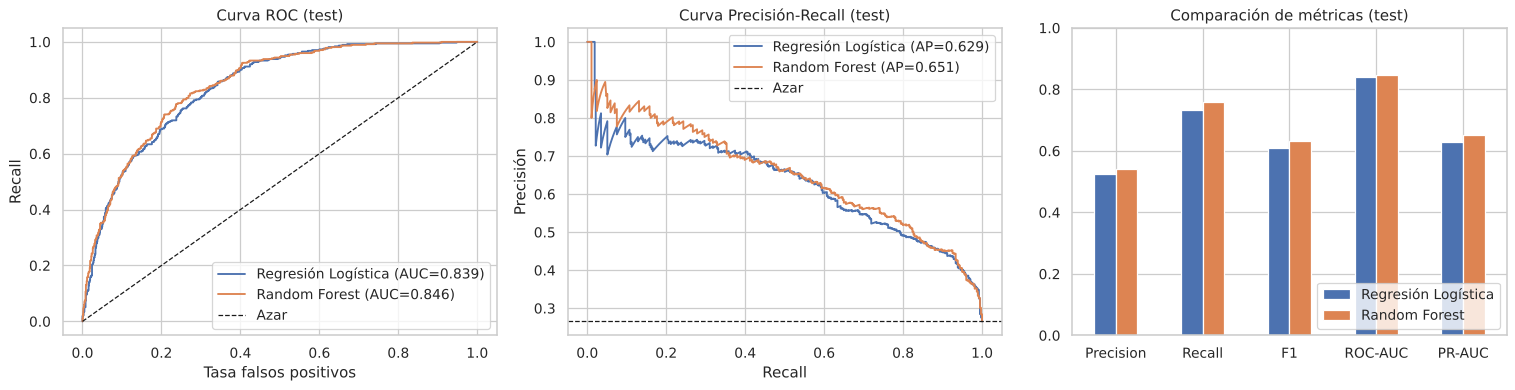

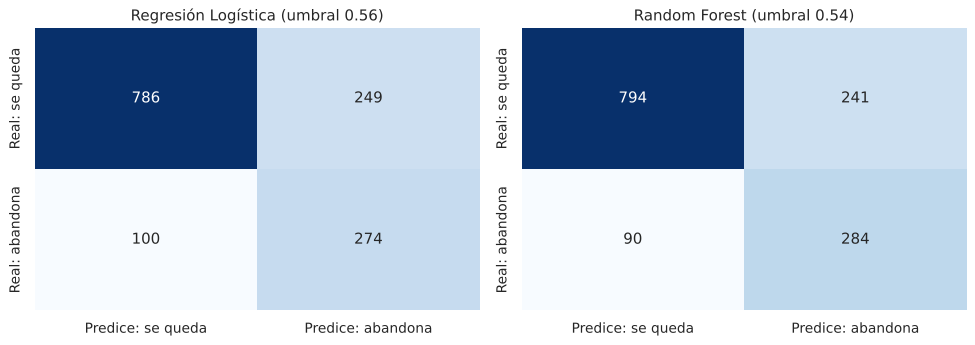

===== Regresión Logística =====
              precision    recall  f1-score   support

    No churn      0.887     0.759     0.818      1035
       Churn      0.524     0.733     0.611       374

    accuracy                          0.752      1409
   macro avg      0.706     0.746     0.715      1409
weighted avg      0.791     0.752     0.763      1409

===== Random Forest =====
              precision    recall  f1-score   support

    No churn      0.898     0.767     0.828      1035
       Churn      0.541     0.759     0.632       374

    accuracy                          0.765      1409
   macro avg      0.720     0.763     0.730      1409
weighted avg      0.803     0.765     0.776      1409



In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for nombre in ["Regresión Logística", "Random Forest"]:
    fpr, tpr, _ = roc_curve(y_test, probas[nombre])
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, probas[nombre]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, probas[nombre])
    axes[1].plot(rc, pr, label=f"{nombre} (AP={average_precision_score(y_test, probas[nombre]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar"); axes[0].set(title="Curva ROC (test)", xlabel="Tasa falsos positivos", ylabel="Recall")
axes[1].axhline(y_test.mean(), ls="--", c="k", lw=1, label="Azar"); axes[1].set(title="Curva Precisión-Recall (test)", xlabel="Recall", ylabel="Precisión")
axes[0].legend(); axes[1].legend()
resultados.drop(index="Baseline (Dummy)")[["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].T.plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Comparación de métricas (test)"); axes[2].set_ylim(0, 1); axes[2].legend(loc="lower right")
guardar_fig("07_roc_pr_comparacion")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nombre in zip(axes, ["Regresión Logística", "Random Forest"]):
    cm = confusion_matrix(y_test, preds[nombre])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predice: se queda", "Predice: abandona"], yticklabels=["Real: se queda", "Real: abandona"])
    ax.set_title(f"{nombre} (umbral {umbrales[nombre]:.2f})")
guardar_fig("08_matrices_confusion")

for nombre in ["Regresión Logística", "Random Forest"]:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, preds[nombre], target_names=["No churn", "Churn"], digits=3))

### 4.3 Interpretabilidad: ¿qué variables explican el churn?

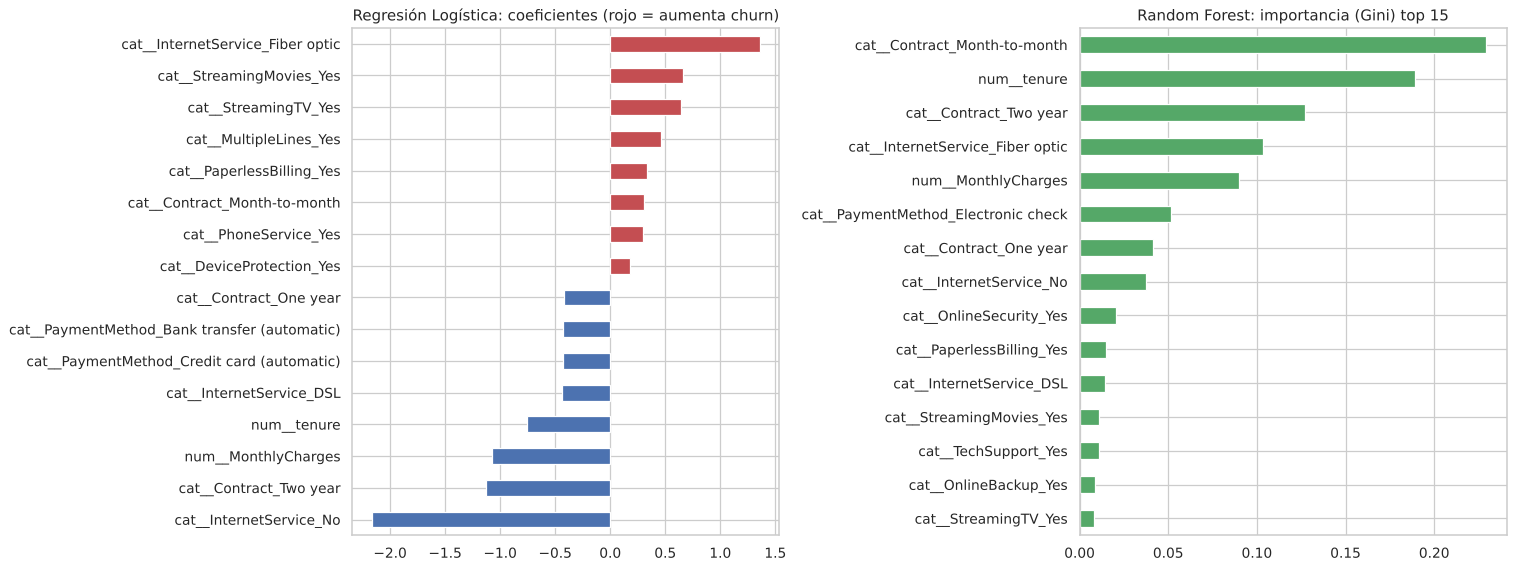

,coef,odds_ratio
cat__InternetService_Fiber optic,1.360,3.898
cat__StreamingMovies_Yes,0.663,1.940
cat__StreamingTV_Yes,0.641,1.898
cat__MultipleLines_Yes,0.459,1.583
cat__PaperlessBilling_Yes,0.330,1.392
cat__Contract_Month-to-month,0.310,1.363
cat__PhoneService_Yes,0.300,1.350
cat__DeviceProtection_Yes,0.175,1.192
cat__Contract_One year,-0.424,0.655
cat__PaymentMethod_Bank transfer (automatic),-0.433,0.649


In [15]:
def nombres_features(pipe):
    return pipe.named_steps["prep"].get_feature_names_out()

lr = modelos["Regresión Logística"]
coef = pd.Series(lr.named_steps["modelo"].coef_[0], index=nombres_features(lr)).sort_values()
rf = modelos["Random Forest"]
imp = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nombres_features(rf)).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
top_coef = pd.concat([coef.head(8), coef.tail(8)])
top_coef.plot.barh(ax=axes[0], color=["#4C72B0" if v < 0 else "#C44E52" for v in top_coef])
axes[0].set_title("Regresión Logística: coeficientes (rojo = aumenta churn)")
imp.tail(15).plot.barh(ax=axes[1], color="#55A868"); axes[1].set_title("Random Forest: importancia (Gini) top 15")
guardar_fig("09_importancia_variables")

odds = np.exp(coef).rename("odds_ratio")
display(pd.concat([coef.rename("coef"), odds], axis=1).loc[top_coef.index[::-1]].round(3))

**Nota de interpretación:** el coeficiente negativo de `MonthlyCharges` en la regresión logística es *condicional* a los servicios: el precio ya está explicado casi por completo por los servicios contratados (fibra, streaming, líneas múltiples, que tienen coeficientes positivos). A igualdad de servicios, el cargo adicional no aumenta el riesgo; el efecto “clientes que pagan más abandonan más” del EDA se captura a través de la fibra óptica y el streaming. Por eso se interpreta en conjunto con el Random Forest.

Ambos modelos coinciden con el EDA: **antigüedad (`tenure`), contrato mes a mes, fibra óptica, ausencia de soporte técnico/seguridad online y pago con cheque electrónico** son los principales impulsores del abandono. Los contratos de 1 y 2 años reducen fuertemente la probabilidad (odds ratio < 1).

## 5. Modelado no supervisado: segmentación de clientes con K-Means

**Objetivo:** descubrir grupos naturales de clientes **sin usar la etiqueta `Churn`**, para luego (a) medir el churn de cada segmento y (b) diseñar acciones de retención diferenciadas.

**Por qué K-Means:** algoritmo de partición simple, escalable e interpretable mediante sus centroides; adecuado para variables continuas escaladas. Las variables se eligieron por su relevancia de negocio en el EDA (valor, antigüedad, vinculación, compromiso contractual):

`tenure`, `MonthlyCharges`, `num_servicios`, `contrato_ord` (0 = mensual, 1 = 1 año, 2 = 2 años), `fibra` (0/1), `pago_automatico` (0/1). Todas se estandarizan (K-Means usa distancia euclidiana).

**Elección de k:** método del codo (inercia) + coeficiente de silueta para k = 2…8.

,inercia,silueta
k,,
2,29489.0,0.293
3,21035.0,0.331
4,16964.0,0.337
5,14485.0,0.351
6,12775.0,0.363
7,11103.0,0.383
8,9910.0,0.386


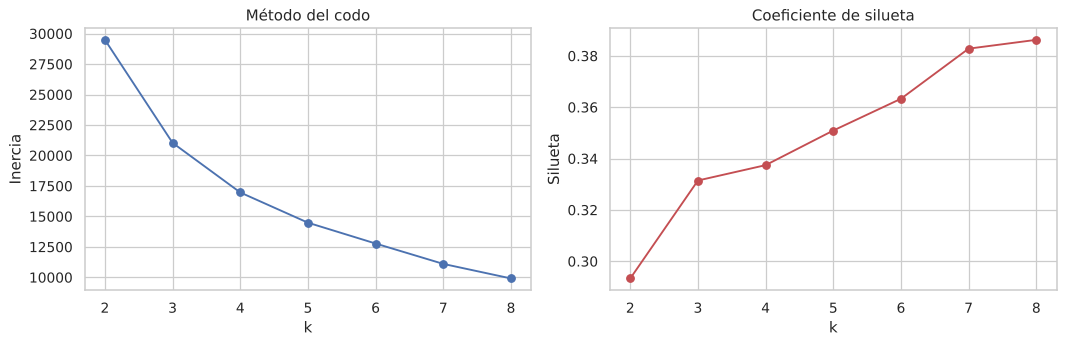

In [16]:
seg = datos.copy()
seg["contrato_ord"] = seg["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
seg["fibra"] = (seg["InternetService"] == "Fiber optic").astype(int)
seg["pago_auto"] = (seg["pago_automatico"] == "Yes").astype(int)
SEG_FEATURES = ["tenure", "MonthlyCharges", "num_servicios", "contrato_ord", "fibra", "pago_auto"]

escalador_seg = StandardScaler()
Z = escalador_seg.fit_transform(seg[SEG_FEATURES])

ks, inercias, siluetas = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=RANDOM_STATE))
display(pd.DataFrame({"k": list(ks), "inercia": np.round(inercias, 0), "silueta": np.round(siluetas, 3)}).set_index("k"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inercias, "o-"); axes[0].set(title="Método del codo", xlabel="k", ylabel="Inercia")
axes[1].plot(list(ks), siluetas, "o-", c="#C44E52"); axes[1].set(title="Coeficiente de silueta", xlabel="k", ylabel="Silueta")
guardar_fig("10_eleccion_k")

**Elección de k = 4.** La silueta crece de forma suave con k (0,29 → 0,39) sin un máximo claro y la curva de inercia muestra el codo entre k = 3 y k = 4; a partir de ahí las reducciones son marginales. Se elige **k = 4** porque (a) está en el codo, (b) su silueta (≈ 0,33–0,34) supera a k = 2 y 3, y (c) produce segmentos **accionables e interpretables** para el área comercial (con k ≥ 6 aparecen grupos pequeños que difieren solo en una variable y no justifican una acción distinta).

In [17]:
K_OPT = 4
kmeans = KMeans(n_clusters=K_OPT, n_init=20, random_state=RANDOM_STATE).fit(Z)
seg["segmento"] = kmeans.labels_
print(f"k = {K_OPT}  |  silueta = {silhouette_score(Z, kmeans.labels_):.3f}")

perfil = seg.groupby("segmento").agg(
    clientes=("customerID", "count"), tenure_medio=("tenure", "mean"), cargo_mensual_medio=("MonthlyCharges", "mean"),
    servicios_medios=("num_servicios", "mean"), pct_mes_a_mes=("contrato_ord", lambda s: (s == 0).mean()),
    pct_fibra=("fibra", "mean"), pct_pago_auto=("pago_auto", "mean"),
    tasa_churn=("Churn", lambda s: (s == "Yes").mean()),
    ingreso_mensual_total=("MonthlyCharges", "sum"))
perfil["pct_clientes"] = perfil["clientes"] / len(seg)
perfil["ingreso_en_riesgo"] = seg[seg.Churn == "Yes"].groupby("segmento")["MonthlyCharges"].sum()
perfil = perfil.sort_values("tasa_churn", ascending=False)
display(perfil.round(2))

k = 4  |  silueta = 0.332


,clientes,tenure_medio,cargo_mensual_medio,servicios_medios,pct_mes_a_mes,pct_fibra,pct_pago_auto,tasa_churn,ingreso_mensual_total,pct_clientes,ingreso_en_riesgo
segmento,,,,,,,,,,,
0,2157,20.63,86.54,2.40,0.94,1.00,0.26,0.54,186675.5,0.31,100397.50
1,2008,13.81,40.40,1.24,0.84,0.00,0.24,0.25,81123.6,0.29,21243.55
3,1659,59.61,91.15,5.07,0.08,0.57,0.74,0.10,151215.3,0.24,16070.55
2,1219,46.65,30.44,1.02,0.01,0.00,0.65,0.03,37102.2,0.17,1419.25


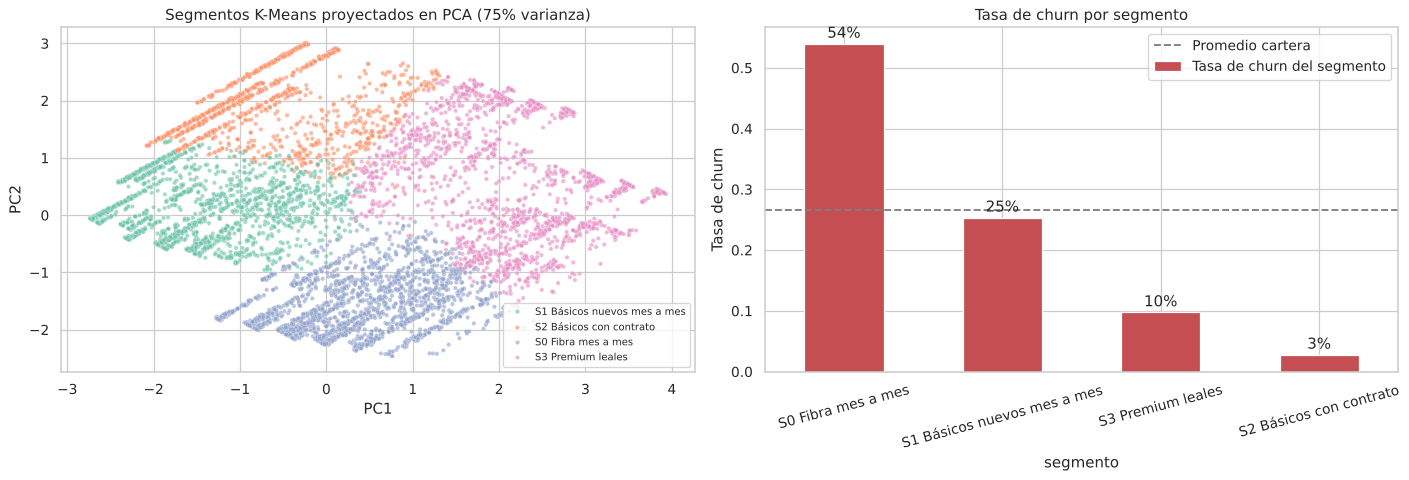

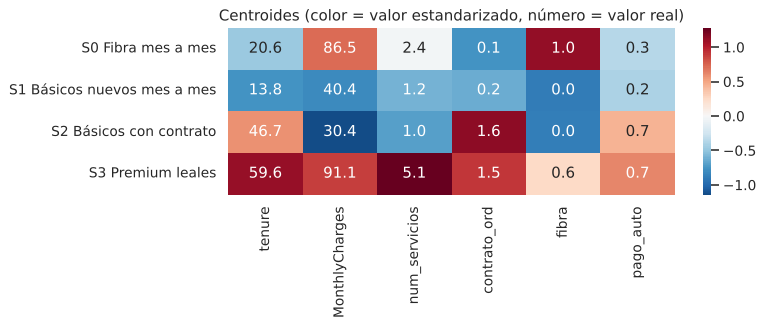

In [18]:
NOMBRES_SEG = {0: "S0 Fibra mes a mes", 1: "S1 Básicos nuevos mes a mes", 2: "S2 Básicos con contrato", 3: "S3 Premium leales"}
seg["segmento_nombre"] = seg["segmento"].map(NOMBRES_SEG)
perfil.index = perfil.index.map(NOMBRES_SEG)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=seg["segmento_nombre"], s=12, alpha=0.6, ax=axes[0], palette="Set2")
axes[0].set(title=f"Segmentos K-Means proyectados en PCA ({pca.explained_variance_ratio_.sum():.0%} varianza)", xlabel="PC1", ylabel="PC2")
axes[0].legend(fontsize=8, loc="best")
perfil["tasa_churn"].plot.bar(ax=axes[1], color="#C44E52", rot=15, label="Tasa de churn del segmento")
axes[1].axhline(seg.Churn.eq("Yes").mean(), ls="--", c="gray", label="Promedio cartera"); axes[1].legend()
axes[1].set(title="Tasa de churn por segmento", ylabel="Tasa de churn")
for i, v in enumerate(perfil["tasa_churn"]): axes[1].text(i, v + 0.01, f"{v:.0%}", ha="center")
guardar_fig("11_segmentos_kmeans")

centroides = pd.DataFrame(escalador_seg.inverse_transform(kmeans.cluster_centers_), columns=SEG_FEATURES)
centroides.index = centroides.index.map(NOMBRES_SEG)
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(pd.DataFrame(kmeans.cluster_centers_, columns=SEG_FEATURES, index=centroides.index), annot=centroides.round(1),
            fmt="", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Centroides (color = valor estandarizado, número = valor real)")
guardar_fig("12_centroides_kmeans")

**Interpretación de los segmentos (la etiqueta `Churn` no se usó para formarlos):**

| Segmento | % cartera | Perfil (centroide) | Churn | Acción de retención propuesta |
|---|---|---|---|---|
| **S0 Fibra mes a mes** | 31 % | ~21 meses, ~USD 87/mes, 100 % fibra, 94 % contrato mensual, poco pago automático | **54 %** | Prioridad 1. Concentra **≈ 72 % del ingreso en riesgo**. Ofrecer migración a contrato anual con descuento, revisar calidad/precio de la fibra, incentivar pago automático. |
| **S1 Básicos nuevos mes a mes** | 29 % | ~14 meses, ~USD 40/mes, DSL o solo telefonía, 1 servicio extra | 25 % | Onboarding durante el primer año, paquetes de seguridad online/soporte técnico a bajo costo (venta cruzada). |
| **S3 Premium leales** | 24 % | ~60 meses, ~USD 91/mes, 5 servicios, contratos largos, pago automático | 10 % | Programa de fidelización y renovación anticipada; proteger por su alto valor. |
| **S2 Básicos con contrato** | 17 % | ~47 meses, ~USD 30/mes, contrato 1–2 años, sin fibra | 3 % | Bajo riesgo: no invertir en retención; oportunidades de upselling. |

La segmentación **confirma y complementa** al modelo supervisado: el riesgo se concentra en clientes con fibra y contrato mensual, y permite diseñar mensajes distintos por grupo en vez de una sola campaña genérica.

## 6. Evaluación
### 6.1 Selección del modelo final

In [19]:
# Criterio: mayor ROC-AUC en validación cruzada (no se elige mirando el test) + cumplimiento de KPIs en test
cv_auc = {k: v.best_score_ for k, v in busquedas.items()}
MODELO_FINAL = max(cv_auc, key=cv_auc.get)
kpis = pd.DataFrame({m: {"Recall >= 0,75": resultados.loc[m, "Recall"] >= 0.75,
                         "ROC-AUC >= 0,80": resultados.loc[m, "ROC-AUC"] >= 0.80,
                         "Lift top 20% >= 2,0": resultados.loc[m, "Lift top 20%"] >= 2.0}
                     for m in ["Regresión Logística", "Random Forest"]})
display(kpis)
print("ROC-AUC CV:", {k: round(v, 4) for k, v in cv_auc.items()})
print("Modelo final seleccionado:", MODELO_FINAL)

,Regresión Logística,Random Forest
"Recall >= 0,75",False,True
"ROC-AUC >= 0,80",True,True
"Lift top 20% >= 2,0",True,True


ROC-AUC CV: {'Regresión Logística': np.float64(0.8451), 'Random Forest': np.float64(0.8476)}
Modelo final seleccionado: Random Forest


| Criterio | Regresión Logística | Random Forest |
|---|---|---|
| ROC-AUC CV (5 folds) | 0,845 ± 0,012 | **0,848 ± 0,010** |
| ROC-AUC test | 0,839 | **0,846** |
| Recall churn test (KPI ≥ 0,75) | 0,733 ✗ | **0,759 ✓** |
| F1 churn test | 0,611 | **0,632** |
| PR-AUC test | 0,629 | **0,651** |
| Lift top 20 % (KPI ≥ 2,0) | 2,51 ✓ | 2,49 ✓ |
| Interpretabilidad | **Alta (coeficientes / odds ratio)** | Media (importancia de variables) |

**Modelo final: Random Forest** — tiene el mejor ROC-AUC en validación cruzada (criterio definido antes de mirar el test), es el único que cumple el KPI de recall y obtiene mejor F1 y PR-AUC. La diferencia entre ambos es pequeña (≈ 0,5–0,7 p.p. de AUC), lo que indica que las relaciones son mayormente lineales; por eso la **Regresión Logística se mantiene como modelo explicativo** para comunicar al negocio la dirección de cada factor.

Ambos superan ampliamente a la línea base (Dummy: recall 0, AUC 0,50). Con el modelo final, de cada 100 clientes que realmente abandonan se detectan ≈ 76; de cada 100 clientes señalados como riesgo, ≈ 54 efectivamente abandonan (vs. 26,5 % si se eligiera al azar).

### 6.2 Traducción a impacto de negocio
Simulación de una campaña de retención sobre los clientes de **test** (1.409). **Supuestos** (explícitos y ajustables por el negocio):
- Costo por cliente contactado (incentivo + gestión): **USD 50**.
- Tasa de éxito de la retención en un cliente que realmente iba a abandonar: **35 %**.
- Valor de retener a un cliente: **12 meses de su `MonthlyCharges`**.

,contactados,churners_detectados,% ingreso en riesgo capturado,ingreso_retenido_USD,costo_USD,beneficio_neto_USD
No hacer nada,0.000000,0.000000,0.0%,0,0,0
Contactar a todos,1409.000000,374.000000,100.0%,"114,303","70,450","43,853"
Regresión Logística,523.000000,274.000000,77.4%,"88,480","26,150","62,330"
Random Forest,525.000000,284.000000,78.3%,"89,505","26,250","63,255"


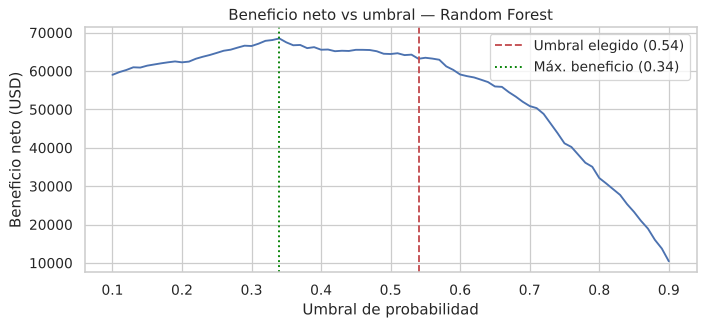

Beneficio con umbral elegido: USD 63,255
Beneficio máximo: USD 68,487 con umbral 0.34


In [20]:
COSTO_CONTACTO, EXITO_RETENCION, MESES_VALOR = 50, 0.35, 12

def beneficio_campana(contactar, y_true, cargo):
    contactar, y_true = np.asarray(contactar).astype(bool), np.asarray(y_true).astype(bool)
    salvados = contactar & y_true
    ingreso = (cargo[salvados] * MESES_VALOR * EXITO_RETENCION).sum()
    costo = contactar.sum() * COSTO_CONTACTO
    return {"contactados": int(contactar.sum()), "churners_detectados": int(salvados.sum()),
            "% ingreso en riesgo capturado": cargo[salvados].sum() / cargo[y_true].sum(),
            "ingreso_retenido_USD": ingreso, "costo_USD": costo, "beneficio_neto_USD": ingreso - costo}

cargo_test = X_test["MonthlyCharges"].values
escenarios = {"No hacer nada": np.zeros(len(y_test)), "Contactar a todos": np.ones(len(y_test)),
              "Regresión Logística": preds["Regresión Logística"], "Random Forest": preds["Random Forest"]}
impacto = pd.DataFrame({k: beneficio_campana(v, y_test, cargo_test) for k, v in escenarios.items()}).T
display(impacto.style.format({"% ingreso en riesgo capturado": "{:.1%}", "ingreso_retenido_USD": "{:,.0f}",
                              "costo_USD": "{:,.0f}", "beneficio_neto_USD": "{:,.0f}"}))

# Sensibilidad del beneficio al umbral (modelo final)
thr_grid = np.linspace(0.1, 0.9, 81)
benef = [beneficio_campana(probas[MODELO_FINAL] >= t, y_test, cargo_test)["beneficio_neto_USD"] for t in thr_grid]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(thr_grid, benef); ax.axvline(umbrales[MODELO_FINAL], ls="--", c="#C44E52", label=f"Umbral elegido ({umbrales[MODELO_FINAL]:.2f})")
ax.axvline(thr_grid[int(np.argmax(benef))], ls=":", c="green", label=f"Máx. beneficio ({thr_grid[int(np.argmax(benef))]:.2f})")
ax.set(title=f"Beneficio neto vs umbral — {MODELO_FINAL}", xlabel="Umbral de probabilidad", ylabel="Beneficio neto (USD)"); ax.legend()
guardar_fig("13_beneficio_vs_umbral")
print(f"Beneficio con umbral elegido: USD {beneficio_campana(probas[MODELO_FINAL] >= umbrales[MODELO_FINAL], y_test, cargo_test)['beneficio_neto_USD']:,.0f}")
print(f"Beneficio máximo: USD {max(benef):,.0f} con umbral {thr_grid[int(np.argmax(benef))]:.2f}")

**Lectura de negocio**
- Con el Random Forest se contacta a **525 de 1.409 clientes (37 %)** y se captura el **78 % del ingreso mensual en riesgo** (KPI ≥ 70 % ✓).
- Beneficio neto estimado ≈ **USD 63.000** en el conjunto de test vs ≈ USD 44.000 de “contactar a todos” (**+44 %**) y con un costo de campaña **63 % menor**.
- La curva de sensibilidad muestra que, con estos supuestos de costos, un umbral más bajo (≈ 0,34) maximizaría el beneficio (≈ USD 68.500) a cambio de contactar a más clientes. **El umbral es una decisión de negocio**: si el presupuesto de retención es limitado conviene el umbral actual; si el costo por contacto es bajo, conviene bajarlo.
- Escalado a la cartera completa (7.043 clientes, ×5), el beneficio potencial es del orden de **USD 300.000 por ciclo de campaña** (estimación sujeta a los supuestos).

### 6.3 Evaluación ética y de sesgo
- **Privacidad:** se eliminó `customerID`; el dataset no contiene nombres, RUT ni datos de contacto. En producción el score debe usarse solo con fines de retención y bajo la normativa de protección de datos (en Chile, Ley 19.628 y Ley 21.719).
- **Atributos sensibles:** `gender` se **excluyó** del modelo. `SeniorCitizen` se mantiene porque tiene relación real con el churn, pero se audita para que la herramienta no derive en trato desfavorable: el modelo solo se usa para **ofrecer beneficios** de retención, nunca para negar servicios o subir precios.
- **Auditoría de equidad:** se compara recall y tasa de falsos positivos por grupo.

In [21]:
def auditoria(grupo):
    filas = []
    for g in sorted(g_test[grupo].unique()):
        mask = (g_test[grupo] == g).values
        yt, yp = y_test.values[mask], preds[MODELO_FINAL][mask]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        filas.append({"variable": grupo, "grupo": g, "n": int(mask.sum()), "tasa_churn_real": yt.mean(),
                      "recall": tp / (tp + fn), "tasa_falsos_positivos": fp / (fp + tn), "precision": tp / max(tp + fp, 1)})
    return filas
equidad = pd.DataFrame(auditoria("gender") + auditoria("SeniorCitizen")).set_index(["variable", "grupo"])
display(equidad.round(3))

# ¿La diferencia de recall entre géneros es estadísticamente significativa? (test z de dos proporciones)
from scipy.stats import norm
churn_g = [(g_test["gender"].values == g) & (y_test.values == 1) for g in ["Female", "Male"]]
n1, n2 = churn_g[0].sum(), churn_g[1].sum()
r1, r2 = preds[MODELO_FINAL][churn_g[0]].mean(), preds[MODELO_FINAL][churn_g[1]].mean()
p_pool = (r1 * n1 + r2 * n2) / (n1 + n2)
z = (r1 - r2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
print(f"Recall Female={r1:.3f} (n={n1})  Male={r2:.3f} (n={n2})  diferencia={abs(r1 - r2) * 100:.1f} p.p.  z={z:.2f}  p-valor={2 * (1 - norm.cdf(abs(z))):.3f}")

n  tasa_churn_real  recall  tasa_falsos_positivos  precision
variable      grupo                                                                  
gender        Female   687            0.281   0.731                  0.221      0.564
              Male     722            0.251   0.790                  0.244      0.520
SeniorCitizen No      1187            0.233   0.728                  0.207      0.515
              Yes      222            0.441   0.847                  0.419      0.615

Recall Female=0.731 (n=193)  Male=0.790 (n=181)  diferencia=5.9 p.p.  z=-1.34  p-valor=0.179


**Resultados de la auditoría**
- **Género:** el recall es 0,73 (Female) vs 0,79 (Male), diferencia de ≈ 6 p.p., levemente sobre la meta de 5 p.p. Sin embargo, el test de dos proporciones indica que **no es estadísticamente significativa** (p > 0,05; solo ≈ 190 churners por grupo en test). Las tasas de falsos positivos son similares (≈ 0,22 vs 0,24). Recomendación: **monitorear** esta métrica con más datos en producción.
- **Adultos mayores:** tienen mayor recall (0,85) y mayor tasa de falsos positivos (0,42) porque su tasa real de churn es mucho mayor (44 % vs 23 %). Como la acción derivada es **ofrecer un beneficio**, recibir más ofertas no los perjudica; sí debe vigilarse que las campañas no sean invasivas (canales y frecuencia de contacto adecuados).
- **Riesgos y mitigaciones:** uso del score solo para retención (no para precios o negación de servicio), revisión humana de las campañas, reentrenamiento periódico (*data drift*), y transparencia con los clientes sobre el uso de sus datos.

## 7. Despliegue: persistencia de artefactos

In [22]:
joblib.dump(modelos[MODELO_FINAL], MODEL_DIR / "modelo_churn_final.joblib")
joblib.dump({"scaler": escalador_seg, "kmeans": kmeans, "features": SEG_FEATURES, "nombres": NOMBRES_SEG},
            MODEL_DIR / "kmeans_segmentacion.joblib")
with open(MODEL_DIR / "config_modelo.json", "w", encoding="utf-8") as f:
    json.dump({"modelo_final": MODELO_FINAL,
               "umbral": round(umbrales[MODELO_FINAL], 4),
               "features_numericas": NUM_FEATURES, "features_categoricas": CAT_FEATURES,
               "random_state": RANDOM_STATE, "metricas_test": resultados.loc[MODELO_FINAL].to_dict()}, f, ensure_ascii=False, indent=2)

# Prueba de carga y scoring de nuevos clientes (ejemplo con 5 clientes de test)
modelo_cargado = joblib.load(MODEL_DIR / "modelo_churn_final.joblib")
ejemplo = X_test.head().copy()
ejemplo["prob_churn"] = modelo_cargado.predict_proba(ejemplo)[:, 1].round(3)
ejemplo["accion"] = np.where(ejemplo["prob_churn"] >= umbrales[MODELO_FINAL], "Contactar (retención)", "Sin acción")
display(ejemplo[["tenure", "Contract", "InternetService", "MonthlyCharges", "prob_churn", "accion"]])

# Lista priorizada de clientes de test para el equipo comercial
lista = datos.loc[X_test.index, ["customerID", "Contract", "tenure", "MonthlyCharges"]].assign(
    prob_churn=probas[MODELO_FINAL].round(4), segmento=seg.loc[X_test.index, "segmento_nombre"].values
).sort_values("prob_churn", ascending=False)
lista.to_csv(BASE / "data" / "scoring_clientes_test.csv", index=False)
print("Artefactos guardados en models/ y data/scoring_clientes_test.csv")

,tenure,Contract,InternetService,MonthlyCharges,prob_churn,accion
437,72,Two year,Fiber optic,114.05,0.046,Sin acción
2280,8,Month-to-month,Fiber optic,100.15,0.860,Contactar (retención)
2235,41,One year,DSL,78.35,0.203,Sin acción
4460,18,Month-to-month,Fiber optic,78.20,0.632,Contactar (retención)
3761,72,Two year,DSL,82.65,0.029,Sin acción


Artefactos guardados en models/ y data/scoring_clientes_test.csv


## 8. Conclusiones y recomendaciones

**Cumplimiento de KPIs (modelo final Random Forest, test):**

| KPI | Meta | Resultado | Estado |
|---|---|---|---|
| Recall churn | ≥ 0,75 | 0,759 | ✓ |
| ROC-AUC | ≥ 0,80 | 0,846 | ✓ |
| Lift top 20 % | ≥ 2,0 | 2,49 | ✓ |
| Ingreso en riesgo capturado | ≥ 70 % | 78 % | ✓ |
| Beneficio neto vs “contactar a todos” | Mayor | +44 % | ✓ |
| Diferencia de recall por género | < 5 p.p. | ≈ 6 p.p. (no significativa) | ⚠ Monitorear |

**Recomendaciones para el negocio**
1. **Migrar clientes mes a mes a contratos anuales** (descuento o beneficio): el contrato es el principal factor de riesgo.
2. **Revisar la propuesta de valor de la fibra óptica** (precio/calidad): 42 % de churn y el segmento S0 concentra ≈ 72 % del ingreso en riesgo.
3. **Ofrecer seguridad online y soporte técnico** como parte de paquetes de retención: su ausencia triplica el churn.
4. **Incentivar el pago automático** frente al cheque electrónico (45 % de churn).
5. **Acompañar a los clientes en su primer año** (onboarding), donde se concentra el abandono.
6. Ejecutar la campaña mensualmente con el score del modelo (`models/modelo_churn_final.joblib`), medir el resultado con un **grupo de control** (A/B) y reentrenar el modelo cada trimestre.

**Limitaciones:** dataset de una sola fotografía temporal (sin historial de interacciones ni reclamos), supuestos económicos estimados y muestra pequeña para auditar subgrupos. Próximos pasos: incorporar datos de uso y atención al cliente, probar Gradient Boosting y calibración de probabilidades.